In [52]:
import torch
from torch import nn
from torchvision.models import alexnet, AlexNet_Weights
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import time
import random
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

repo_dir = next(
    path
    for path in (Path("."), Path(".."), Path("../.."), Path("../../.."))
    if (path / "实践1" / "outer1.png").is_file()
)
project_dir = repo_dir / "实践2" / "CNN"

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

EPOCHS = 10
LR = 0.0003

# 下载AlecNet
weights_alexnet = AlexNet_Weights.DEFAULT
model_alexnet = alexnet(weights=weights_alexnet)

device_alexnet = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_alexnet = model_alexnet.to(device_alexnet)
model_alexnet.eval()

conv_layers_alexnet = [
    (i, layer)
    for i, layer in enumerate(model_alexnet.features)
    if isinstance(layer, nn.Conv2d)
]

first_conv_alexnet = conv_layers_alexnet[0][1]
last_conv_alexnet = conv_layers_alexnet[-1][1]

print("\n第一层：", first_conv_alexnet)
print("最后一层：", last_conv_alexnet)
print("计算设备：", device_alexnet)


第一层： Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
最后一层： Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
计算设备： cuda


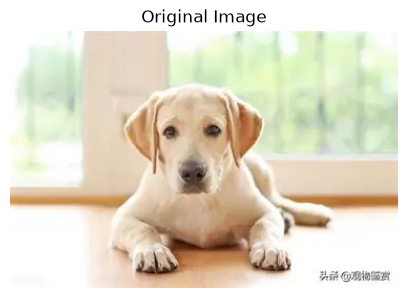

In [6]:
# 展示图片，导入官方预处理
image_path_alexnet = repo_dir / "images" / "test.jpg"

with Image.open(image_path_alexnet) as img:
    image_alexnet = img.convert("RGB")

preprocess_alexnet = weights_alexnet.transforms()
image_tensor_alexnet = preprocess_alexnet(image_alexnet)
input_alexnet = image_tensor_alexnet.unsqueeze(0).to(
    device_alexnet
)

plt.figure(figsize=(5, 4))
plt.imshow(image_alexnet)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [9]:
# 提取第一层和最后一层卷积特征图
feature_maps_alexnet = {}

x = input_alexnet

model_alexnet.eval()

with torch.inference_mode():

    for index, layer in enumerate(model_alexnet.features):
        x = layer(x)

        if index == 0:
            feature_maps_alexnet["first"] = x.cpu()

        if index == 10:
            feature_maps_alexnet["last"] = x.cpu()

first_features_alexnet = feature_maps_alexnet["first"]
last_features_alexnet = feature_maps_alexnet["last"]

print("第一层卷积输出：", first_features_alexnet.shape)
print("最后一层卷积输出：", last_features_alexnet.shape)

第一层卷积输出： torch.Size([1, 64, 55, 55])
最后一层卷积输出： torch.Size([1, 256, 13, 13])


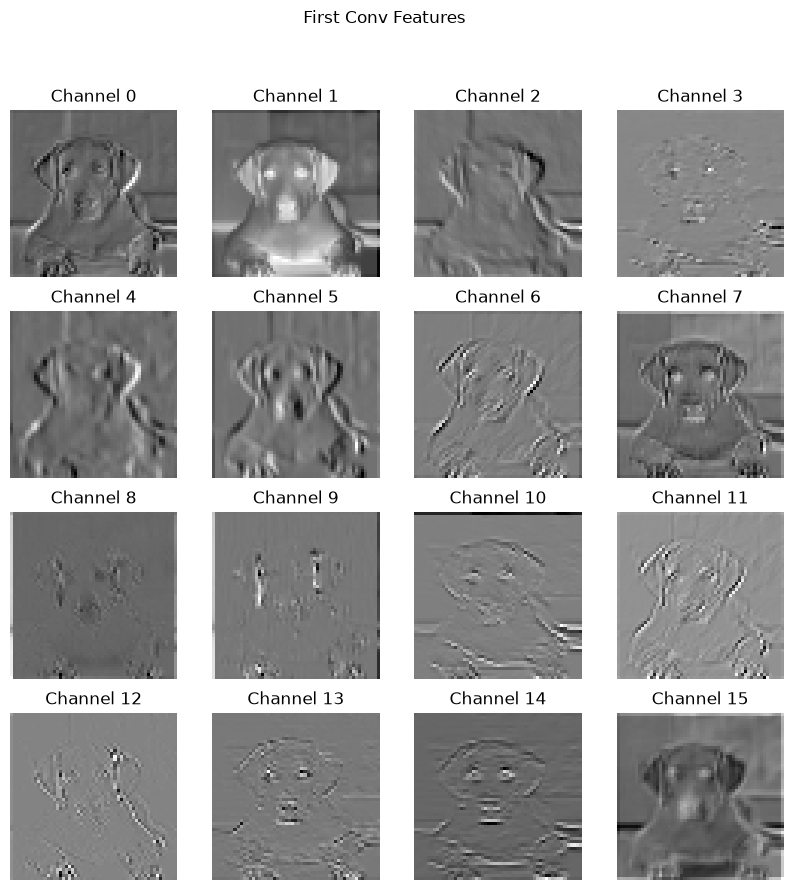

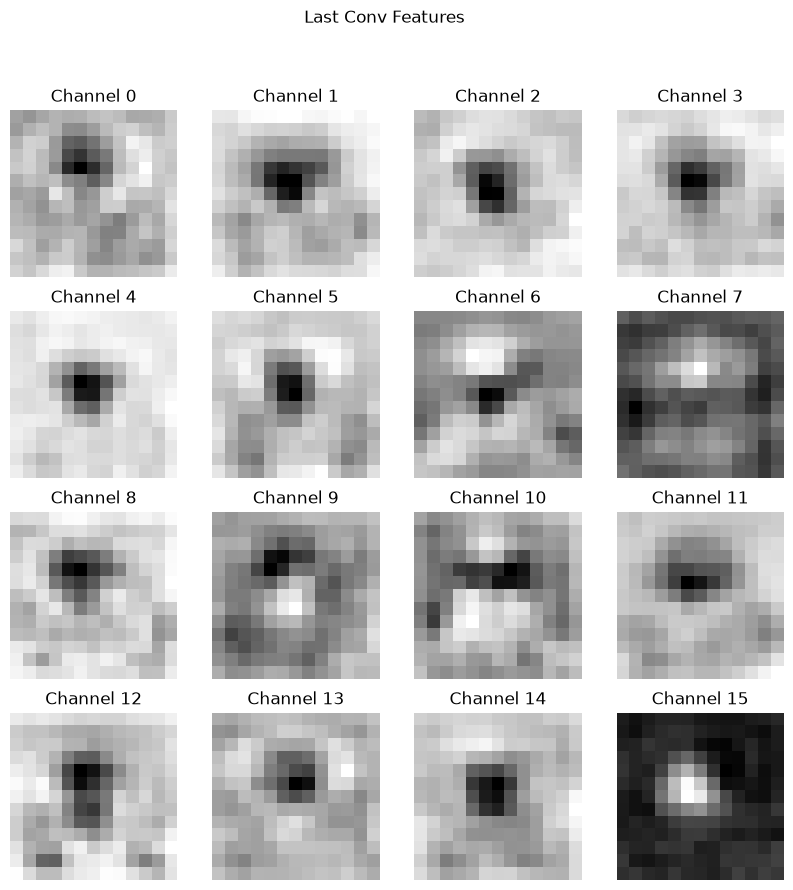

In [53]:
# 展示特征图
def show_feature_maps(features, title, n=16):
    n = min(n, features.shape[1])

    fig, axes = plt.subplots(4, 4, figsize=(10, 10))
    axes = axes.flatten()

    for i in range(16):
        ax = axes[i]

        if i < n:
            feature = features[0, i].detach().cpu().numpy()

            ax.imshow(feature, cmap="gray")
            ax.set_title(f"Channel {i}")

        ax.axis("off")

    fig.suptitle(title)
    plt.show()

show_feature_maps(
    first_features_alexnet,
    "First Conv Features"
)

show_feature_maps(
    last_features_alexnet,
    "Last Conv Features"
)

In [18]:
# 计算两组特征输出L2范数
first_norms_alexnet = torch.linalg.vector_norm(
    first_features_alexnet,
    ord=2,
    dim=(2, 3)
)

last_norms_alexnet = torch.linalg.vector_norm(
    last_features_alexnet,
    ord=2,
    dim=(2, 3)
)

for name, norms in [
    ("First Conv", first_norms_alexnet),
    ("Last Conv", last_norms_alexnet)
]:
    values = norms[0]

    print(f"\n{name}")
    print(f"通道数：{values.numel()}")
    print(f"最大L2范数：{values.max().item():}")
    print(f"最小L2范数：{values.min().item():}")
    print(f"平均L2范数：{values.mean().item():}")

    top_values, top_indices = torch.topk(values, k=5)

    print("响应最强的5个通道：")
    for index, value in zip(top_indices, top_values):
        print(f"Channel{index.item()}:{value.item():}")


First Conv
通道数：64
最大L2范数：441.22393798828125
最小L2范数：12.057278633117676
平均L2范数：94.21832275390625
响应最强的5个通道：
Channel36:441.22393798828125
Channel1:385.43463134765625
Channel39:180.34225463867188
Channel15:176.6710662841797
Channel19:154.58990478515625

Last Conv
通道数：256
最大L2范数：167.67623901367188
最小L2范数：26.137826919555664
平均L2范数：87.3676528930664
响应最强的5个通道：
Channel208:167.67623901367188
Channel1:153.38690185546875
Channel89:150.52102661132812
Channel139:148.25302124023438
Channel206:145.12779235839844


In [46]:
# Bottleneck替换实验
# 原始CNN：
class CNN(nn.Module):

    def __init__(self):
        super().__init__()
    
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
    
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
    
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
    
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# 添加Bottleneck CNN：
class Bottleneck(nn.Module):
    def __init__(self, in_channels, mid_channels, out_channels):
        super().__init__()

        self.residual = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(),

            nn.Conv2d(mid_channels, mid_channels,
                      kernel_size=3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(),

            nn.Conv2d(mid_channels, out_channels, kernel_size=1),
            nn.BatchNorm2d(out_channels)
        )

        self.shortcut = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1),
            nn.BatchNorm2d(out_channels)
        )

        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.residual(x) + self.shortcut(x))


class CNNBottleneck(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # 第三卷积块替换
            Bottleneck(32, 16, 64),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [47]:
# 参数量统计
def count_params(model):
    return sum(p.numel() for p in model.parameters())

baseline = CNN()
bottleneck_model = CNNBottleneck()

params_baseline = count_params(baseline)
params_bottleneck = count_params(bottleneck_model)

print(f"原始CNN：{params_baseline:,}")
print(f"Bottleneck CNN：{params_bottleneck:,}")

原始CNN：2,169,618
Bottleneck CNN：2,120,562


In [48]:
# 训练函数
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def run_experiment(model, train_loader, val_loader, epochs=10, lr=0.001):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    epoch_times = []

    for epoch in range(epochs):
        model.train()

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start
        epoch_times.append(elapsed)

        print(
            f"Epoch{epoch+1}/{epochs}:"
            f"训练耗时：{elapsed}s"
        )

    model.eval()

    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total

    return {
        "params": count_params(model),
        "total_time": sum(epoch_times),
        "accuracy": accuracy
    }

In [54]:
# dataloader
split_dir = project_dir / "data" / "split"

transform = transforms.Compose([
    transforms.RandomResizedCrop(
        128,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.5,
        contrast=0.5,
        saturation=0.2
    ),
    transforms.ToTensor()
])

transform1 = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    root=split_dir / "train",
    transform=transform
)

val_dataset = datasets.ImageFolder(
    root=split_dir / "val",
    transform=transform1
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("训练集样本数：", len(train_dataset))
print("验证集样本数：", len(val_dataset))

训练集样本数： 17498
验证集样本数： 3750


In [51]:
# 训练对比
# 原始CNN
print("baseline")
set_seed(42)

result_baseline = run_experiment(
    CNN(),
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=LR
)

# Bottleneck CNN
print("\nBottleneck CNN")
set_seed(42)

result_bottleneck = run_experiment(
    CNNBottleneck(),
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=LR
)


print(
    "参数量：\n"
    f"baseline：{result_baseline['params']}\n"
    f"bottleneck：{result_bottleneck['params']}"
)

print(
    "\n总训练时间(s)："
)
print(
    f"baseline：{result_baseline['total_time']}\n"
    f"bottleneck：{result_bottleneck['total_time']}"
)

print(
    "\n验证集准确率："
)
print(
    f"baseline：{result_baseline['accuracy'] * 100}%\n"
    f"bottleneck：{result_bottleneck['accuracy'] * 100}%"
)

baseline
Epoch1/10:训练耗时：39.90051920001861s
Epoch2/10:训练耗时：40.179449500050396s
Epoch3/10:训练耗时：40.38711449992843s
Epoch4/10:训练耗时：40.361805099993944s
Epoch5/10:训练耗时：41.44750720006414s
Epoch6/10:训练耗时：41.01033079996705s
Epoch7/10:训练耗时：41.32716700003948s
Epoch8/10:训练耗时：41.10211860004347s
Epoch9/10:训练耗时：40.67409950005822s
Epoch10/10:训练耗时：40.846933299908414s

Bottleneck CNN
Epoch1/10:训练耗时：41.32332669990137s
Epoch2/10:训练耗时：41.78388040000573s
Epoch3/10:训练耗时：41.380168800009415s
Epoch4/10:训练耗时：41.75482130004093s
Epoch5/10:训练耗时：41.65641880000476s
Epoch6/10:训练耗时：41.674766000011005s
Epoch7/10:训练耗时：41.5370623000199s
Epoch8/10:训练耗时：41.56738020002376s
Epoch9/10:训练耗时：41.63997769996058s
Epoch10/10:训练耗时：41.70586629991885s
参数量：
baseline：2169618
bottleneck：2120562

总训练时间(s)：
baseline：407.24
bottleneck：416.02

验证集准确率：
baseline：80.93%
bottleneck：66.64%


In [ ]:
# 手写AlexNet结构
class AlexNet(nn.Module):
    def __init__(self, num_classes=1000):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            
            nn.Conv2d(96, 256, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(384, 384, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(),

            nn.Dropout(0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(),

            nn.Linear(4096, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x


model = AlexNet(num_classes=1000)